### Top Rows

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

file_path = "results-filtered-dataset.csv"
df = pd.read_csv(file_path)


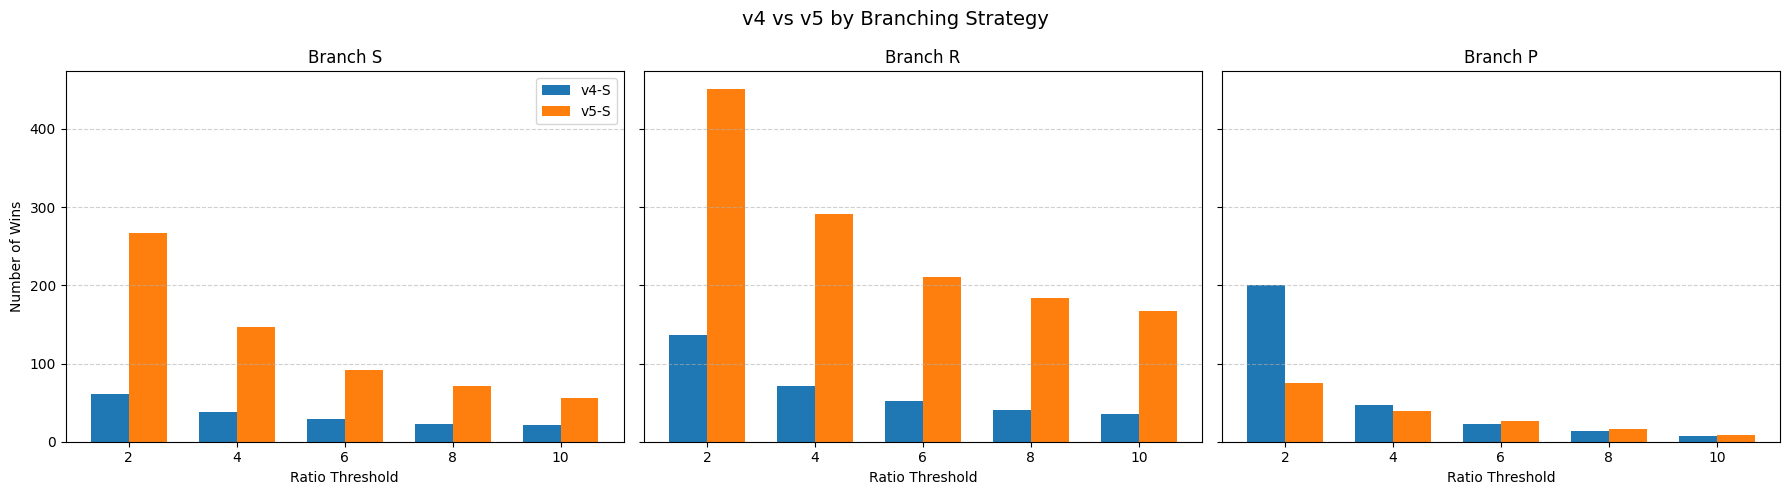

In [5]:
from IPython.display import display, Markdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

group1 = 'v4'
group2 = 'v5'
branchings = ['S', 'R', 'P']

ratio_thresholds = [2, 4, 6, 8, 10]

fig, axes = plt.subplots(1, len(branchings), figsize=(18,5), sharey=True)

for i, br in enumerate(branchings):

    col1 = f"{group1}-{br}"
    col2 = f"{group2}-{br}"

    if col1 not in df.columns or col2 not in df.columns:
        continue

    df[[col1, col2]] = (
        df[[col1, col2]]
        .replace("x", 1800)
        .apply(pd.to_numeric, errors="coerce")
    )

    den = np.minimum(df[col1], df[col2]).replace(0, np.nan)
    df["ratio"] = np.maximum(df[col1], df[col2]) / den

    group1_wins_list = []
    group2_wins_list = []

    for r in ratio_thresholds:

        filtered_rows = df[
            (df[col1] > 1) &
            (df[col2] > 1) &
            (df["ratio"] >= r)
        ]

        group1_wins = (filtered_rows[col1] < filtered_rows[col2]).sum()
        group2_wins = len(filtered_rows) - group1_wins

        group1_wins_list.append(group1_wins)
        group2_wins_list.append(group2_wins)

    x = np.arange(len(ratio_thresholds))
    width = 0.35

    ax = axes[i]

    ax.bar(x - width/2, group1_wins_list, width, label=f"{group1}-{br}")
    ax.bar(x + width/2, group2_wins_list, width, label=f"{group2}-{br}")

    ax.set_xticks(x)
    ax.set_xticklabels(ratio_thresholds)
    ax.set_xlabel("Ratio Threshold")
    ax.set_title(f"Branch {br}")
    ax.grid(axis="y", linestyle="--", alpha=0.6)

    if i == 0:
        ax.set_ylabel("Number of Wins")

axes[0].legend()

plt.suptitle(f"{group1} vs {group2} by Branching Strategy", fontsize=14)
plt.tight_layout()
plt.show()

### Varying Ratio Threshold

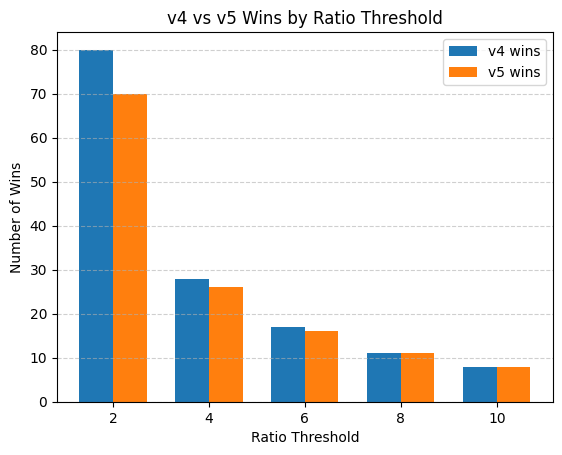

In [109]:
ratio_thresholds = [2, 4, 6, 8, 10]

group1_wins_list = []
group2_wins_list = []

den = np.minimum(df[f"{group1}_min"], df[f"{group2}_min"])
df["ratio"] = np.maximum(df[f"{group1}_min"], df[f"{group2}_min"]) / den.replace(0, np.nan)

for r in ratio_thresholds:
    filtered_rows = df[
        (df[f"{group1}_min"] > 1) &
        (df[f"{group2}_min"] > 1) &
        (df["ratio"] >= r)
    ]

    total = len(filtered_rows)

    group1_wins = (filtered_rows[f"{group1}_min"] < filtered_rows[f"{group2}_min"]).sum()
    group2_wins = total - group1_wins

    group1_wins_list.append(group1_wins)
    group2_wins_list.append(group2_wins)

# Plot
x = np.arange(len(ratio_thresholds))
width = 0.35

plt.figure()

plt.bar(x - width/2, group1_wins_list, width, label=f"{group1} wins")
plt.bar(x + width/2, group2_wins_list, width, label=f"{group2} wins")

plt.xticks(x, [f"{r}" for r in ratio_thresholds])
plt.xlabel("Ratio Threshold")
plt.ylabel("Number of Wins")
plt.title(f"{group1} vs {group2} Wins by Ratio Threshold")

plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.show()